# CS-4063 Natural Language Processing — Assignment 1
## Language Modeling for Urdu News Articles (BBC Urdu)

**Student:** i25-8029 &nbsp;&nbsp; **Section:** MSDS-3a


In [1]:
import os, re, json, time, math, random, html, unicodedata
from collections import Counter, defaultdict, deque
from datetime import datetime, timezone
from urllib.parse import urljoin
import requests
from bs4 import BeautifulSoup
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, HTML

random.seed(42)
os.makedirs("plots", exist_ok=True)
MIN_ARTICLES, TARGET_ARTICLES, MAX_ARTICLES = 200, 260, 300
print("Setup complete.")

Setup complete.


---
# PART 1 — BBC Urdu Dataset Collection and Preprocessing
## 1. Dataset Collection (Scraper)


In [2]:
BASE = "https://www.bbc.com"
HOME = "https://www.bbc.com/urdu"
SEED_PAGES = [HOME, HOME + "/pakistan", HOME + "/world", HOME + "/sport",
              HOME + "/science", HOME + "/entertainment", HOME + "/popular/read"]
HEADERS = {"User-Agent": ("Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 "
                          "(KHTML, like Gecko) Chrome/124.0 Safari/537.36"),
           "Accept-Language": "ur,en;q=0.8"}
ARTICLE_RE = re.compile(r"^https://www\.bbc\.com/urdu/(articles/[a-z0-9]{8,}|[a-z0-9\-]+-\d{8})$")
URDU_LETTER_RE = re.compile(r"[\u0600-\u06FF]")
SESSION = requests.Session()


def fetch(url, retries=3, delay=1.0, timeout=15):
    """GET a page with retries and back-off. Returns HTML text or None."""
    for attempt in range(1, retries + 1):
        try:
            r = SESSION.get(url, headers=HEADERS, timeout=timeout)
            if r.status_code == 200:
                r.encoding = "utf-8"
                return r.text
            if r.status_code in (403, 404, 410):
                return None
        except requests.RequestException:
            pass
        time.sleep(delay * attempt)
    return None


def normalize_url(href):
    return urljoin(BASE, href).split("#")[0].split("?")[0].rstrip("/")


def extract_article_links(page_html):
    soup = BeautifulSoup(page_html, "html.parser")
    links = []
    for a in soup.find_all("a", href=True):
        u = normalize_url(a["href"])
        if ARTICLE_RE.match(u) and u not in links:
            links.append(u)
    return links


def parse_article(page_html, url):
    soup = BeautifulSoup(page_html, "html.parser")
    title_tag = soup.find("h1")
    og = soup.find("meta", property="og:title")
    title = title_tag.get_text(" ", strip=True) if title_tag else (og["content"] if og else "")
    t = soup.find("time", attrs={"datetime": True})
    pub = soup.find("meta", property="article:published_time")
    date = t["datetime"] if t else (pub["content"] if pub else "unknown")
    sec = soup.find("meta", property="article:section")
    m = re.match(r"https://www\.bbc\.com/urdu/([a-z\-]+)-\d{8}$", url)
    category = sec["content"] if sec and sec.get("content") else (m.group(1) if m else "عمومی")

    main = soup.find("main") or soup.find("article") or soup.body
    if main is None:
        return None
    for tag in main.find_all(["nav", "aside", "header", "footer", "script", "style", "noscript"]):
        tag.decompose()
    for s in main.find_all("section"):
        label = " ".join([s.get("aria-labelledby") or "", " ".join(s.get("class") or []), s.get("data-e2e") or ""])
        if re.search(r"related|recommend|most-read|podcast|features", label, re.I):
            s.decompose()
    blocks = []
    for el in main.find_all(["h2", "p", "figcaption"]):
        if el.find_parent(["p", "figcaption"]):      # avoid duplicate nested text
            continue
        txt = el.get_text(" ")
        if txt.strip():
            blocks.append(txt)
    body = "\n".join(blocks)
    return {"title": title, "url": url, "category": category, "published_date": date,
            "body": body, "source": "BBC Urdu (live scrape)"}


def is_complete(art):
    urdu_words = [w for w in art["body"].split() if URDU_LETTER_RE.search(w)]
    return len(urdu_words) >= 120 and bool(art["title"])


def crawl(target=TARGET_ARTICLES, max_pages=1500, delay=1.0, verbose=True):
    frontier, seen, articles = deque(), set(), []
    for page in SEED_PAGES:
        h = fetch(page)
        if h:
            frontier.extend(extract_article_links(h))
        time.sleep(delay)
    visited = 0
    while frontier and len(articles) < target and visited < max_pages:
        url = frontier.popleft()
        if url in seen:
            continue
        seen.add(url); visited += 1
        h = fetch(url)
        time.sleep(delay)
        if not h:
            continue
        try:
            art = parse_article(h, url)
        except Exception as e:           # malformed page -> skip
            art = None
        if art and is_complete(art):
            art["scraped_at"] = datetime.now(timezone.utc).isoformat(timespec="seconds")
            articles.append(art)
            if verbose and len(articles) % 20 == 0:
                print(f"  collected {len(articles)} articles (visited {visited} pages)")
        frontier.extend(u for u in extract_article_links(h) if u not in seen)
    return articles


def internet_ok():
    return fetch(HOME, retries=1, timeout=8) is not None

In [3]:
CACHE = "scraped_articles.json"
DATA_SOURCE = None
if os.path.exists(CACHE):
    articles = json.load(open(CACHE, encoding="utf-8"))
    DATA_SOURCE = articles[0].get("source", "cache")
    print(f"Loaded {len(articles)} cached articles ({DATA_SOURCE}).")
elif internet_ok():
    print("BBC Urdu reachable - crawling ...")
    articles = crawl()
    articles = articles[:MAX_ARTICLES]
    json.dump(articles, open(CACHE, "w", encoding="utf-8"), ensure_ascii=False, indent=1)
    DATA_SOURCE = "BBC Urdu (live scrape)"
    print(f"Scraped {len(articles)} complete articles.")
else:
    articles = []

if len(articles) < MIN_ARTICLES:
    # ------------------------------------------------------------------
    # APPROXIMATION / LIMITATION FLAG:
    # BBC Urdu could not be reached from this environment, so the rest of
    # the pipeline is demonstrated on a clearly labeled SYNTHETIC sample.
    # Re-run this cell with internet access (delete scraped_articles.json)
    # to use real BBC articles; nothing else in the notebook changes.
    # ------------------------------------------------------------------
    from sample_corpus import build_sample_corpus
    print("!! BBC Urdu not reachable (or <200 articles). Using SYNTHETIC SAMPLE corpus (offline fallback).")
    articles = build_sample_corpus(n_articles=250)
    for a in articles:
        a["scraped_at"] = datetime.now(timezone.utc).isoformat(timespec="seconds")
    DATA_SOURCE = "SYNTHETIC_SAMPLE"

print("Data source:", DATA_SOURCE, "| articles:", len(articles))

BBC Urdu reachable - crawling ...
  collected 20 articles (visited 23 pages)
  collected 40 articles (visited 46 pages)
  collected 60 articles (visited 77 pages)
  collected 80 articles (visited 109 pages)
  collected 100 articles (visited 132 pages)
  collected 120 articles (visited 152 pages)
  collected 140 articles (visited 172 pages)
  collected 160 articles (visited 192 pages)
  collected 180 articles (visited 213 pages)
  collected 200 articles (visited 234 pages)
  collected 220 articles (visited 255 pages)
  collected 240 articles (visited 275 pages)
  collected 260 articles (visited 295 pages)
Scraped 260 complete articles.
Data source: BBC Urdu (live scrape) | articles: 260


### 1.1 Output files: `Metadata.json` and `raw.txt`
Article numbers are assigned once (1…N) and reused for all three files. `Metadata.json` holds metadata only — **no body text**. `raw.txt` holds the untouched bodies, one block per article, each starting with `### Article <n> ###`.

In [4]:
metadata = []
for i, a in enumerate(articles, start=1):
    a["article_number"] = i
    metadata.append({"article_number": i, "title": a["title"], "url": a["url"],
                     "category": a["category"], "published_date": a["published_date"],
                     "scraped_at": a["scraped_at"], "source": a["source"]})
json.dump(metadata, open("Metadata.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)

with open("raw.txt", "w", encoding="utf-8") as f:
    for a in articles:
        f.write(f"### Article {a['article_number']} ###\n{a['body']}\n\n")

assert len({m["article_number"] for m in metadata}) == len(metadata)       # unique numbering
assert all("body" not in m for m in metadata)                               # no body in JSON
print(json.dumps(metadata[:2], ensure_ascii=False, indent=2))
print("\n--- raw.txt (first 600 chars) ---")
print(open("raw.txt", encoding="utf-8").read()[:600])

[
  {
    "article_number": 1,
    "title": "سہیل احمد: جس بچے کے لیے بولنا ناممکن تھا، آج وہ دوسروں کو ان کی آواز دے رہا ہے",
    "url": "https://www.bbc.com/urdu/articles/c3ew97e79e18o",
    "category": "عمومی",
    "published_date": "2026-09-20",
    "scraped_at": "2026-09-20T17:15:56+00:00",
    "source": "BBC Urdu (live scrape)"
  },
  {
    "article_number": 2,
    "title": "’تیل کی قلت ہوئی تو شاید 1000 روپے فی لیٹر بھی نہ ملے‘: مشرقِ وسطیٰ میں کشیدگی اور وزیر پیٹرولیم کا انتباہ",
    "url": "https://www.bbc.com/urdu/articles/cjn5dgqv9ww4o",
    "category": "عمومی",
    "published_date": "2026-09-19",
    "scraped_at": "2026-09-20T17:15:57+00:00",
    "source": "BBC Urdu (live scrape)"
  }
]

--- raw.txt (first 600 chars) ---
### Article 1 ###
،تصویر کا ذریعہ Sohail Ahmed
،تصویر کا کیپشن سہیل 'ایک ایسا لڑکا جس کے پاس آواز نہیں تھی' کے عنوان سے خطاب کریں گے۔
پانچ سالہ سہیل احمد دیکھ سکتے تھے کہ ان کے آس پاس موجود لوگ بیتابی سے ان کے بولنے کا انتظار کر رہے ہیں۔ وہ ان کی ہدایات اپن

## 2. Data Cleaning and Normalization


In [5]:
CHAR_MAP = {"\u064A": "\u06CC", "\u0649": "\u06CC", "\u0643": "\u06A9", "\u0647": "\u06C1",
            "?": "؟", ",": "،", ";": "؛", "\u066B": ".", "\u066C": ","}


def normalize_unicode(text):
    text = unicodedata.normalize("NFC", text)
    # Arabic presentation forms (FB50-FDFF, FE70-FEFF) -> base letters
    text = "".join(unicodedata.normalize("NFKC", c) if "\uFB50" <= c <= "\uFEFF" else c for c in text)
    return "".join(CHAR_MAP.get(c, c) for c in text)


ex = "يہ رپورٹ كراچی ميں تيار ہوئی?"
print("BEFORE:", ex, [hex(ord(c)) for c in ex[:2]])
print("AFTER :", normalize_unicode(ex), [hex(ord(c)) for c in normalize_unicode(ex)[:2]])

BEFORE: يہ رپورٹ كراچی ميں تيار ہوئی? ['0x64a', '0x6c1']
AFTER : یہ رپورٹ کراچی میں تیار ہوئی؟ ['0x6cc', '0x6c1']


### 2.1 Diacritics Removal


In [6]:
DIACRITICS_RE = re.compile("[\u064B-\u0653\u0656-\u065F\u0670\u06D6-\u06DC\u06DF-\u06E8\u06EA-\u06ED\u0640]")


def remove_diacritics(text):
    return DIACRITICS_RE.sub("", text)


for w in ["عِلم", "حُکومت", "مُحَمَّد", "پاکِستان"]:
    print(f"{w:>10}  ->  {remove_diacritics(w):<10} | same as plain form: {remove_diacritics(w) in ('علم','حکومت','محمد','پاکستان')}")

      عِلم  ->  علم        | same as plain form: True
    حُکومت  ->  حکومت      | same as plain form: True
  مُحَمَّد  ->  محمد       | same as plain form: True
  پاکِستان  ->  پاکستان    | same as plain form: True


### 2.2 Noise Removal (URLs, emojis, web artifacts, boilerplate)


In [7]:
URL_RE = re.compile(r"(https?://\S+|www\.\S+|\b[\w\-]+\.(?:com|org|net|pk|co\.uk|tv)\S*)", re.I)
EMAIL_RE = re.compile(r"\S+@\S+\.\S+")
HANDLE_RE = re.compile(r"[@#]\w+")
EMOJI_RE = re.compile("[\U0001F000-\U0001FAFF\u2600-\u27BF\u2B00-\u2BFF\uFE0F\u200D\u20E3]")
TAG_RE = re.compile(r"<[^>]+>")
BOILERPLATE_LINE_RE = re.compile(
    r"^\s*(،?\s*تصویر کا ذریعہ|،?\s*تصویر کا کیپشن|،?\s*ویڈیو کیپشن|یہ بھی پڑھیے|مزید پڑھیے|"
    r"متعلقہ عنوانات|سب سے زیادہ پڑھی جانے والی|بی بی سی اردو کی خبروں کو اپنے فون پر|شیئر کریں)")


def remove_noise(text):
    text = html.unescape(TAG_RE.sub(" ", text))
    text = URL_RE.sub(" ", text)
    text = EMAIL_RE.sub(" ", text)
    text = HANDLE_RE.sub(" ", text)
    text = EMOJI_RE.sub(" ", text)
    lines = [ln for ln in text.split("\n") if not BOILERPLATE_LINE_RE.match(ln)]
    return "\n".join(lines)


ex = "بریکنگ نیوز Visit www.bbc.com 📢\n،تصویر کا ذریعہGetty Images\nمزید تفصیلات https://bbc.com/urdu/x پر"
print("BEFORE:\n" + ex)
print("AFTER:\n" + remove_noise(ex))

BEFORE:
بریکنگ نیوز Visit www.bbc.com 📢
،تصویر کا ذریعہGetty Images
مزید تفصیلات https://bbc.com/urdu/x پر
AFTER:
بریکنگ نیوز Visit    
مزید تفصیلات   پر


### 2.3 Removal of Non-Urdu Text (English / Roman Urdu)


In [8]:
LATIN_RE = re.compile(r"[A-Za-z\u00C0-\u024F][A-Za-z\u00C0-\u024F'’\-\.]*")
ALLOWED_RE = re.compile(r"[^\u0600-\u06FF\u0750-\u077F0-9\u06F0-\u06F9\u0660-\u0669\u200C\s۔،؟؛!:\"'()\.\-%]")


def remove_non_urdu(text):
    text = LATIN_RE.sub(" ", text)
    return ALLOWED_RE.sub(" ", text)


ex = "یہ رپورٹ breaking news کے بارے میں ہے، yeh bhi parhiye (Reuters) ✓"
print("BEFORE:", ex)
print("AFTER :", re.sub(r" +", " ", remove_non_urdu(ex)))

BEFORE: یہ رپورٹ breaking news کے بارے میں ہے، yeh bhi parhiye (Reuters) ✓
AFTER : یہ رپورٹ کے بارے میں ہے، ( ) 


### 2.4 Whitespace and Formatting Normalization


In [9]:
def normalize_whitespace(text):
    text = re.sub("[\u00A0\u2000-\u200B\u202F\u205F\u3000\uFEFF\u200D\u200E\u200F]", " ", text)
    text = re.sub("\u200C+", "\u200C", text)
    text = re.sub(r"[ \t]+", " ", text)
    text = re.sub(r" +([۔،؟؛!:])", r"\1", text)
    lines = [ln.strip() for ln in text.split("\n")]
    return "\n".join(ln for ln in lines if ln)


ex = "پاکستان   میں\t\tبارش    ہوئی  ۔\n\n\n   لوگ    متاثر ہوئے ۔ "
print("BEFORE:", repr(ex))
print("AFTER :", repr(normalize_whitespace(ex)))

BEFORE: 'پاکستان   میں\t\tبارش    ہوئی  ۔\n\n\n   لوگ    متاثر ہوئے ۔ '
AFTER : 'پاکستان میں بارش ہوئی۔\nلوگ متاثر ہوئے۔'


### 2.5 Sentence Segmentation


In [10]:
SENT_SPLIT_RE = re.compile(r"(?<=[۔؟!])\s*|(?<=[\u0600-\u06FF])\.(?=\s|$)")


def segment_sentences(text):
    sents = []
    for para in text.split("\n"):
        for part in SENT_SPLIT_RE.split(para):
            part = (part or "").strip(" .")
            if not part:
                continue
            n_words = len([w for w in part.split() if URDU_LETTER_RE.search(w)])
            if part[-1] not in "۔؟!":
                if n_words < 4:
                    continue
                part += "۔"
            if n_words >= 3:
                sents.append(part)
    return sents


ex = "پاکستان میں بارش ہوئی۔ لوگ متاثر ہوئے۔ کیا حکومت مدد کرے گی؟ حکام نے امداد کا اعلان کیا"
print("BEFORE:", ex)
print("AFTER :")
for s in segment_sentences(ex):
    print("   ", s)

BEFORE: پاکستان میں بارش ہوئی۔ لوگ متاثر ہوئے۔ کیا حکومت مدد کرے گی؟ حکام نے امداد کا اعلان کیا
AFTER :
    پاکستان میں بارش ہوئی۔
    لوگ متاثر ہوئے۔
    کیا حکومت مدد کرے گی؟
    حکام نے امداد کا اعلان کیا۔


### 2.6 Full cleaning pipeline applied to one article

In [11]:
def clean_text(raw):
    t = normalize_unicode(raw)
    t = remove_noise(t)
    t = remove_diacritics(t)
    t = remove_non_urdu(t)
    t = normalize_whitespace(t)
    return segment_sentences(t)


sample = articles[0]["body"]
print("RAW (first 500 chars):\n", sample[:500])
print("\nCLEANED SENTENCES (first 6):")
for s in clean_text(sample)[:6]:
    print("  ", s)

RAW (first 500 chars):
 ،تصویر کا ذریعہ Sohail Ahmed
،تصویر کا کیپشن سہیل 'ایک ایسا لڑکا جس کے پاس آواز نہیں تھی' کے عنوان سے خطاب کریں گے۔
پانچ سالہ سہیل احمد دیکھ سکتے تھے کہ ان کے آس پاس موجود لوگ بیتابی سے ان کے بولنے کا انتظار کر رہے ہیں۔ وہ ان کی ہدایات اپنے ذہن میں سن سکتے تھے، لیکن الفاظ تھے کہ ان کے منھ سے نکلنے کو تیار نہیں تھے۔
وہ کہتے ہیں کہ ’جب میں ماضی کو یاد کرتا ہوں تو یوں لگتا ہے جیسے میں مفلوج تھا۔ آپ حقیقت میں وہاں موجود ہوتے ہیں، لیکن ایک ہی وقت میں وہاں موجود نہیں ہوتے۔ آپ کمرے میں ہوتے ہیں، لیکن ی

CLEANED SENTENCES (first 6):
   پانچ سالہ سہیل احمد دیکھ سکتے تھے کہ ان کے آس پاس موجود لوگ بیتابی سے ان کے بولنے کا انتظار کر رہے ہیں۔
   وہ ان کی ہدایات اپنے ذہن میں سن سکتے تھے، لیکن الفاظ تھے کہ ان کے منھ سے نکلنے کو تیار نہیں تھے۔
   وہ کہتے ہیں کہ جب میں ماضی کو یاد کرتا ہوں تو یوں لگتا ہے جیسے میں مفلوج تھا۔
   آپ حقیقت میں وہاں موجود ہوتے ہیں، لیکن ایک ہی وقت میں وہاں موجود نہیں ہوتے۔
   آپ کمرے میں ہوتے ہیں، لیکن یوں لگتا ہے جیسے آپ کمرے میں ہیں ہی نہیں۔
   سب 

## 3. Custom Linguistic Processing
### 3.1 Custom Urdu Tokenizer

In [12]:
PUNCT = "۔،؟؛!:\"'()[]{}«»“”‘’-–—…/*|"
DIGITS = "0-9\u06F0-\u06F9\u0660-\u0669"
TOKEN_RE = re.compile(rf"[{DIGITS}]+(?:[\.,٫٬][{DIGITS}]+)*%?|[{re.escape(PUNCT)}]|[^\s{DIGITS}{re.escape(PUNCT)}]+")
NUM_RE = re.compile(rf"^[{DIGITS}]+(?:[\.,٫٬][{DIGITS}]+)*%?$")
POSTPOSITIONS = {"کا", "کی", "کے", "میں", "سے", "پر", "نے", "کو", "تک", "لیے", "ساتھ", "بعد", "پہلے",
                 "طرف", "مطابق", "دوران", "خلاف", "بارے", "جانب", "بغیر", "علاوہ", "ذریعے", "والا", "والی", "والے"}
GLUED_POSTPOSITIONS = {"کیلئے": ["کے", "لیے"], "کیلیے": ["کے", "لیے"], "کےلیے": ["کے", "لیے"],
                       "کےلئے": ["کے", "لیے"], "لئے": ["لیے"], "کیطرف": ["کی", "طرف"], "کےساتھ": ["کے", "ساتھ"]}


def tokenize(sentence):
    tokens = []
    for tok in TOKEN_RE.findall(sentence):
        if NUM_RE.match(tok):
            tokens.append("<NUM>")
            continue
        if tok == "ء" and tokens and tokens[-1] == "<NUM>":      # 2025ء -> <NUM>
            continue
        if tok in GLUED_POSTPOSITIONS:
            tokens.extend(GLUED_POSTPOSITIONS[tok]); continue
        if "\u200C" in tok:                                       # ZWNJ-attached postposition
            head, _, tail = tok.rpartition("\u200C")
            if tail in POSTPOSITIONS and head:
                tokens.extend([head, tail]); continue
            tok = tok.replace("\u200C", "")
        tokens.append(tok)
    return tokens


for s in ["حکومت نے 2025ء میں پیٹرول کی قیمت میں ۱۵ روپے اضافہ کیا۔",
          "شہریوں کیلئے 3.5% رعایت کا اعلان، کیا یہ کافی ہے؟",
          "وزیراعظم نے (اسلام آباد) میں پاکستان\u200Cکے عوام سے خطاب کیا!"]:
    print(s, "\n  ->", tokenize(s))

حکومت نے 2025ء میں پیٹرول کی قیمت میں ۱۵ روپے اضافہ کیا۔ 
  -> ['حکومت', 'نے', '<NUM>', 'میں', 'پیٹرول', 'کی', 'قیمت', 'میں', '<NUM>', 'روپے', 'اضافہ', 'کیا', '۔']
شہریوں کیلئے 3.5% رعایت کا اعلان، کیا یہ کافی ہے؟ 
  -> ['شہریوں', 'کے', 'لیے', '<NUM>', 'رعایت', 'کا', 'اعلان', '،', 'کیا', 'یہ', 'کافی', 'ہے', '؟']
وزیراعظم نے (اسلام آباد) میں پاکستان‌کے عوام سے خطاب کیا! 
  -> ['وزیراعظم', 'نے', '(', 'اسلام', 'آباد', ')', 'میں', 'پاکستان', 'کے', 'عوام', 'سے', 'خطاب', 'کیا', '!']


### 3.2 Custom Urdu Lemmatizer (plural & gender normalization)


In [13]:
LEMMA_TABLE = {
    "ممالک": "ملک", "افراد": "فرد", "مسائل": "مسئلہ", "وسائل": "وسیلہ", "تجاویز": "تجویز", "خواتین": "خاتون",
    "اخبارات": "اخبار", "واقعات": "واقعہ", "معاملات": "معاملہ", "خدشات": "خدشہ", "اعلانات": "اعلان",
    "طلبہ": "طالب", "علما": "عالم", "اساتذہ": "استاد", "حکام": "حاکم", "اقدامات": "اقدام",
    "خدمات": "خدمت", "اوقات": "وقت", "انتخابات": "انتخاب", "حالات": "حال", "تعلقات": "تعلق",
    "تنازعات": "تنازع", "برآمدات": "برآمد", "درآمدات": "درآمد", "تحقیقات": "تحقیق", "خیالات": "خیال",
    "مذاکرات": "مذاکرہ", "ادویات": "دوا", "شکایات": "شکایت", "ہدایات": "ہدایت", "سہولیات": "سہولت",
    "کارروائیاں": "کارروائی", "گھنٹوں": "گھنٹہ", "حصوں": "حصہ", "علاقوں": "علاقہ", "لوگوں": "لوگ", "گئی": "گیا", "گئے": "گیا", "گئیں": "گیا", "ہوئی": "ہوا", "ہوئے": "ہوا", "ہوئیں": "ہوا",
    "رہی": "رہا", "رہے": "رہا", "تھی": "تھا", "تھے": "تھا", "تھیں": "تھا", "کیے": "کیا", "کئے": "کیا",
    "دی": "دیا", "دیے": "دیا", "دئیے": "دیا", "گی": "گا", "گے": "گا", "سکتی": "سکتا", "سکتے": "سکتا",
    "اپنی": "اپنا", "اپنے": "اپنا", "بڑی": "بڑا", "بڑے": "بڑا", "نئی": "نیا", "نئے": "نیا",
    "پہلی": "پہلا", "دوسری": "دوسرا", "دوسرے": "دوسرا", "والی": "والا", "والے": "والا",
    "ایسی": "ایسا", "ایسے": "ایسا", "کیسی": "کیسا", "کیسے": "کیسا", "جیسی": "جیسا", "جیسے": "جیسا",
}
# Function words that must never be changed (postpositions, auxiliaries, pronouns, particles)
PROTECTED = POSTPOSITIONS - {"والا", "والی", "والے"} | {
    "ہے", "ہیں", "ہوں", "نہیں", "نہ", "بھی", "ہی", "تو", "اور", "یا", "کہ", "جو", "یہ", "وہ", "اس", "ان",
    "انھیں", "انھوں", "انہوں", "انہیں", "ہم", "آپ", "میں", "کریں", "جائیں", "کیں", "گئیں", "سی", "کسی", "کئی",
    "ابھی", "یہی", "وہی", "کبھی", "سبھی", "کوئی", "لیکن", "مگر", "چاہیے", "تاہم", "بلکہ", "<NUM>",
    "کیوں", "دونوں", "نمایاں", "عیاں", "میاں", "موسمیات", "معاشیات", "سیاسیات", "تینوں", "یوں", "کروں", "جاؤں", "ملاقات", "کائنات", "نجات", "حیات", "مساوات", "اوقات"} | set(PUNCT)
URDU_TOKEN_RE = re.compile(r"^[\u0600-\u06FF\u0750-\u077F]+$")


class UrduLemmatizer:
    # (suffix, candidate replacements, default used when no candidate is attested)
    RULES = [("یاں", ["ی"], "ی"), ("یوں", ["ی"], "ی"), ("ؤں", [""], ""), ("ائیں", ["ا"], None),
             ("وں", ["ہ", "ا", ""], None), ("ات", ["", "ہ", "ت"], None), ("یں", [""], None),
             ("ے", ["ہ", "ا"], None), ("ی", ["ا"], None)]

    def __init__(self, vocab_counts):
        self.vocab = vocab_counts          # Counter of surface forms in the corpus

    def lemmatize(self, tok):
        if tok in PROTECTED or not URDU_TOKEN_RE.match(tok):
            return tok
        if tok in LEMMA_TABLE:
            return LEMMA_TABLE[tok]
        for suf, reps, default in self.RULES:
            if tok.endswith(suf) and len(tok) - len(suf) >= (3 if suf == "ات" else 2):
                stem = tok[: -len(suf)]
                cands = [stem + r for r in reps if (stem + r) in self.vocab and stem + r != tok]
                # oblique evidence: if stem+ے is attested, the direct form is stem+ہ (علاقوں/علاقے -> علاقہ)
                if suf == "وں" and (stem + "ے") in self.vocab and (stem + "ہ") not in cands:
                    cands.append(stem + "ہ")
                if cands:
                    return max(cands, key=lambda c: self.vocab.get(c, 0))
                if default is not None:
                    return stem + default
        return tok

### 3.3 Custom Urdu Stemmer (suffix stripping)


In [14]:
class UrduStemmer:
    NOMINAL = ["یوں", "یاں", "ائیں", "وں", "یں", "ات"]
    VERBAL = ["تا", "تی", "تے", "نا", "نی", "نے", "گا", "گی", "گے"]
    DERIV = ["یت"]
    MIN_STEM = 3

    def __init__(self, vocab_counts):
        self.vocab = vocab_counts

    def _attested(self, stem, family):
        return stem in self.vocab or sum((stem + s) in self.vocab for s in family) >= 2

    def stem(self, tok):
        if tok in PROTECTED or not URDU_TOKEN_RE.match(tok) or tok in POSTPOSITIONS:
            return tok
        for family in (self.NOMINAL, self.VERBAL, self.DERIV):
            for suf in sorted(family, key=len, reverse=True):
                if tok.endswith(suf) and len(tok) - len(suf) >= self.MIN_STEM:
                    stem = tok[: -len(suf)]
                    if self._attested(stem, family):
                        return stem
        return tok

### 3.4 Building `cleaned.txt`


In [15]:
# Pass 1: clean + tokenize everything, collect surface vocabulary for the validated rules
tokenized = {}
surface_vocab = Counter()
for a in articles:
    sents = [tokenize(s) for s in clean_text(a["body"])]
    sents = [s for s in sents if sum(1 for t in s if t not in PUNCT) >= 3]
    tokenized[a["article_number"]] = sents
    for s in sents:
        surface_vocab.update(s)

lemmatizer = UrduLemmatizer(surface_vocab)
lemma_vocab = Counter()
for sents in tokenized.values():
    for s in sents:
        lemma_vocab.update(lemmatizer.lemmatize(t) for t in s)
stemmer = UrduStemmer(lemma_vocab)


def process_tokens(tokens):
    return [stemmer.stem(lemmatizer.lemmatize(t)) for t in tokens]


processed = {n: [process_tokens(s) for s in sents] for n, sents in tokenized.items()}
with open("cleaned.txt", "w", encoding="utf-8") as f:
    for a in articles:
        n = a["article_number"]
        f.write(f"### Article {n} ###\n")
        for s in processed[n]:
            f.write(" ".join(s) + "\n")
        f.write("\n")

# surface -> final token map (used by the GUI to preprocess seed prompts identically)
json.dump({w: process_tokens([w])[0] for w in surface_vocab}, open("token_map.json", "w", encoding="utf-8"),
          ensure_ascii=False)

n_sents = sum(len(v) for v in processed.values())
n_toks = sum(len(s) for v in processed.values() for s in v)
print(f"Articles: {len(processed)} | sentences: {n_sents} | tokens: {n_toks}")
print(f"Vocabulary  surface: {len(surface_vocab)}  ->  after lemmatizer: {len(lemma_vocab)}  ->  after stemmer: "
      f"{len(Counter(t for v in processed.values() for s in v for t in s))}")
print("\n--- cleaned.txt (first 700 chars) ---")
print(open("cleaned.txt", encoding="utf-8").read()[:700])

Articles: 260 | sentences: 16170 | tokens: 443471
Vocabulary  surface: 15148  ->  after lemmatizer: 13033  ->  after stemmer: 12556

--- cleaned.txt (first 700 chars) ---
### Article 1 ###
پانچ سالہ سہیل احمد دیکھ سکتا تھا کہ ان کے آس پاس موجود لوگ بیتابی سے ان کے بول کا انتظار کر رہا ہیں ۔
وہ ان کی ہدایت اپنا ذہن میں سن سکتا تھا ، لیکن الفاظ تھا کہ ان کے منھ سے نکل کو تیار نہیں تھا ۔
وہ کہتا ہیں کہ جب میں ماضی کو یاد کرتا ہوں تو یوں لگتا ہے جیسا میں مفلوج تھا ۔
آپ حقیقت میں وہاں موجود ہوتا ہیں ، لیکن ایک ہی وقت میں وہاں موجود نہیں ہوتا ۔
آپ کمرہ میں ہوتا ہیں ، لیکن یوں لگتا ہے جیسا آپ کمرہ میں ہیں ہی نہیں ۔
سب لوگ آپ کے کچھ کہنا کا انتظار کر رہا ہوتا ہیں ۔
آپ خود کو ایسا دیکھ ہیں جیسا باہر سے خود کو دیکھ رہا ہوں اور خود سے کہتا ہیں چلو ، کچھ بولو ، لیکن آپ بول نہیں پاتا ، آپ سے بولا ہی نہیں جاتا ۔
اب چار دہائی سے زیادہ عرصہ بعد بریڈفورڈ کے جنرل پریکٹیشنر اور


### 3.5 Component demos (tokenizer, lemmatizer, stemmer in isolation)

In [16]:
demo_words = ["لڑکیاں", "شہریوں", "علاقوں", "رہنماؤں", "حالات", "ادارے", "ممالک", "خواتین", "گئی", "ہوئے", "تھیں",
              "بڑی", "حکومتوں", "انتخابات", "کسانوں", "فصلیں", "دیکھتا", "کی", "میں", "نہیں"]
rows = [(w, lemmatizer.lemmatize(w), stemmer.stem(lemmatizer.lemmatize(w))) for w in demo_words]
html_rows = "".join(f"<tr><td>{a}</td><td>{b}</td><td>{c}</td></tr>" for a, b, c in rows)
display(HTML(f"<table dir='rtl' style='font-size:15px'><tr><th>Surface</th><th>Lemma</th><th>Lemma → Stem</th></tr>{html_rows}</table>"))
s = "حکومت نے 2024 میں شہریوں کیلئے نئی اسکیموں کا اعلان کیا تھا۔"
print("Sentence :", s)
print("Tokens   :", tokenize(s))
print("Lemmas   :", [lemmatizer.lemmatize(t) for t in tokenize(s)])
print("Final    :", process_tokens(tokenize(s)))

Surface,Lemma,Lemma → Stem
لڑکیاں,لڑکی,لڑکی
شہریوں,شہری,شہری
علاقوں,علاقہ,علاقہ
رہنماؤں,رہنما,رہنما
حالات,حال,حال
ادارے,ادارہ,ادارہ
ممالک,ملک,ملک
خواتین,خاتون,خاتون
گئی,گیا,گیا
ہوئے,ہوا,ہوا


Sentence : حکومت نے 2024 میں شہریوں کیلئے نئی اسکیموں کا اعلان کیا تھا۔
Tokens   : ['حکومت', 'نے', '<NUM>', 'میں', 'شہریوں', 'کے', 'لیے', 'نئی', 'اسکیموں', 'کا', 'اعلان', 'کیا', 'تھا', '۔']
Lemmas   : ['حکومت', 'نے', '<NUM>', 'میں', 'شہری', 'کے', 'لیے', 'نیا', 'اسکیموں', 'کا', 'اعلان', 'کیا', 'تھا', '۔']
Final    : ['حکومت', 'نے', '<NUM>', 'میں', 'شہری', 'کے', 'لیے', 'نیا', 'اسکیموں', 'کا', 'اعلان', 'کیا', 'تھا', '۔']


### 3.6 Consistency check across the three Part-1 files

In [17]:
def headers(path):
    return [int(m) for m in re.findall(r"^### Article (\d+) ###", open(path, encoding="utf-8").read(), re.M)]

meta_ids = [m["article_number"] for m in json.load(open("Metadata.json", encoding="utf-8"))]
print("Metadata.json :", len(meta_ids), "articles, ids", meta_ids[0], "...", meta_ids[-1])
print("raw.txt       :", len(headers("raw.txt")), "blocks")
print("cleaned.txt   :", len(headers("cleaned.txt")), "blocks")
print("Numbering identical in all three files:", meta_ids == headers("raw.txt") == headers("cleaned.txt"))
print("Body text absent from JSON:", all(set(m) == {"article_number", "title", "url", "category",
      "published_date", "scraped_at", "source"} for m in json.load(open("Metadata.json", encoding="utf-8"))))

Metadata.json : 260 articles, ids 1 ... 260
raw.txt       : 260 blocks
cleaned.txt   : 260 blocks
Numbering identical in all three files: True
Body text absent from JSON: True


---
# PART 2 — BBC-Style Urdu News Article Generation


In [18]:
BOS, EOS, UNK = "<s>", "</s>", "<UNK>"


class UnigramLM:
    order = 1

    def __init__(self, sentences, k=1.0):
        self.k = k
        self.counts = Counter()
        for s in sentences:
            self.counts.update(s + [EOS])
        self.vocab = set(self.counts) | {EOS, UNK}
        self.V = len(self.vocab)
        self.N = sum(self.counts.values())

    def map(self, w):
        return w if w in self.vocab else UNK

    def prob(self, w, history=()):
        return (self.counts[self.map(w)] + self.k) / (self.N + self.k * self.V), 1

    def candidates(self, history=()):
        return {w: c for w, c in self.counts.items()}, 1


class BigramLM(UnigramLM):
    order = 2

    def __init__(self, sentences, k=1.0):
        super().__init__(sentences, k)
        self.bi = defaultdict(Counter)
        for s in sentences:
            seq = [BOS] + s + [EOS]
            for u, w in zip(seq, seq[1:]):
                self.bi[u][w] += 1
        self.bi_tot = {u: sum(c.values()) for u, c in self.bi.items()}

    def prob(self, w, history=()):
        v = history[-1] if history else BOS
        v = v if v in self.bi else self.map(v)
        w = self.map(w)
        if v in self.bi:                                       # bigram context seen
            return (self.bi[v][w] + self.k) / (self.bi_tot[v] + self.k * self.V), 2
        return UnigramLM.prob(self, w)                          # back off to unigram

    def candidates(self, history=()):
        v = history[-1] if history else BOS
        if v in self.bi:
            return self.bi[v], 2
        return UnigramLM.candidates(self)


class TrigramLM(BigramLM):
    order = 3

    def __init__(self, sentences, k=1.0):
        super().__init__(sentences, k)
        self.tri = defaultdict(Counter)
        for s in sentences:
            seq = [BOS, BOS] + s + [EOS]
            for u, v, w in zip(seq, seq[1:], seq[2:]):
                self.tri[(u, v)][w] += 1
        self.tri_tot = {h: sum(c.values()) for h, c in self.tri.items()}

    def prob(self, w, history=()):
        h = tuple(([BOS, BOS] + list(history))[-2:])
        if h in self.tri:                                       # trigram context seen
            return (self.tri[h][self.map(w)] + self.k) / (self.tri_tot[h] + self.k * self.V), 3
        return BigramLM.prob(self, w, history)                  # back off -> bigram -> unigram

    def candidates(self, history=()):
        h = tuple(([BOS, BOS] + list(history))[-2:])
        if h in self.tri:
            return self.tri[h], 3
        return BigramLM.candidates(self, history)


def perplexity(model, sentences):
    log_sum, n = 0.0, 0
    for s in sentences:
        hist = []
        for w in s + [EOS]:
            p, _ = model.prob(w, hist)
            log_sum += math.log(p); n += 1
            hist.append(w)
    return math.exp(-log_sum / n)

### 4.1 Train / held-out split and choice of k
Articles are split 90 % / 10 % (by article, seeded). Held-out perplexity is computed for Laplace (k = 1) and several Add-k values; the best k is used for the final models.

train sentences: 14580 | test sentences: 1590
      k |   Unigram |    Bigram | Trigram+backoff
-------------------------------------------------
    1.0 |    672.66 |    850.20 |         2632.38   (Laplace)
    0.5 |    681.87 |    614.02 |         1985.86
    0.1 |    708.56 |    338.66 |         1036.50
   0.05 |    720.87 |    284.71 |          807.34
   0.01 |    750.45 |    231.22 |          520.44
  0.005 |    763.58 |    228.52 |          466.04

Best k per model: {'Unigram': 1.0, 'Bigram': 0.005, 'Trigram+backoff': 0.005}


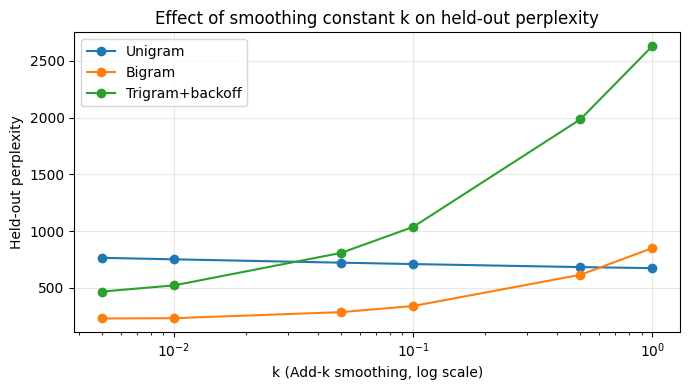

In [19]:
all_ids = sorted(processed)
rng_split = random.Random(0)
test_ids = set(rng_split.sample(all_ids, max(1, len(all_ids) // 10)))
train_sents = [s for n in all_ids if n not in test_ids for s in processed[n]]
test_sents = [s for n in all_ids if n in test_ids for s in processed[n]]
print(f"train sentences: {len(train_sents)} | test sentences: {len(test_sents)}")

K_VALUES = [1.0, 0.5, 0.1, 0.05, 0.01, 0.005]
ppl_table = {}
for k in K_VALUES:
    ppl_table[k] = {name: perplexity(cls(train_sents, k), test_sents)
                    for name, cls in [("Unigram", UnigramLM), ("Bigram", BigramLM), ("Trigram+backoff", TrigramLM)]}

hdr = f"{'k':>7} | {'Unigram':>9} | {'Bigram':>9} | {'Trigram+backoff':>15}"
print(hdr); print("-" * len(hdr))
for k, r in ppl_table.items():
    print(f"{k:>7} | {r['Unigram']:>9.2f} | {r['Bigram']:>9.2f} | {r['Trigram+backoff']:>15.2f}" + ("   (Laplace)" if k == 1 else ""))
BEST_K = {m: min(K_VALUES, key=lambda k: ppl_table[k][m]) for m in ["Unigram", "Bigram", "Trigram+backoff"]}
print("\nBest k per model:", BEST_K)

fig, ax = plt.subplots(figsize=(7, 4))
for m in ["Unigram", "Bigram", "Trigram+backoff"]:
    ax.plot(K_VALUES, [ppl_table[k][m] for k in K_VALUES], marker="o", label=m)
ax.set_xscale("log"); ax.set_xlabel("k (Add-k smoothing, log scale)"); ax.set_ylabel("Held-out perplexity")
ax.set_title("Effect of smoothing constant k on held-out perplexity"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig("plots/ppl_vs_k.png", dpi=150); plt.show()

### 4.2 Sanity checks: no zero probabilities & backoff in action

In [20]:
uni = UnigramLM(train_sents, BEST_K["Unigram"])
bi_eval = BigramLM(train_sents, BEST_K["Bigram"])
tri_eval = TrigramLM(train_sents, BEST_K["Trigram+backoff"])

# 1) every probability > 0, and distributions sum to 1 for a seen and an unseen context
h_seen = next(iter(tri_eval.tri))
for name, hist in [("seen trigram history", list(h_seen)), ("unseen history", ["زززز", "ققققق"])]:
    total = sum(tri_eval.prob(w, hist)[0] for w in tri_eval.vocab)
    pmin = min(tri_eval.prob(w, hist)[0] for w in tri_eval.vocab)
    print(f"{name:<22} level used={tri_eval.prob('ہے', hist)[1]}  sum P = {total:.6f}  min P = {pmin:.2e} (>0)")

# 2) backoff chain on concrete histories
for hist in [["محکمہ", "موسمیات"], ["زلزلہ", "کے"], ["زلزلہ", "جھٹکا"]]:
    p, level = tri_eval.prob("کے", hist)
    used = {3: "TRIGRAM", 2: "BIGRAM (backoff)", 1: "UNIGRAM (backoff)"}[level]
    print(f"history {hist} -> uses {used:<18}  P(کے | history) = {p:.3e}")

# 3) backoff statistics on the held-out set
lvl = Counter()
for s in test_sents:
    hist = []
    for w in s + [EOS]:
        lvl[tri_eval.prob(w, hist)[1]] += 1; hist.append(w)
tot = sum(lvl.values())
print("\nHeld-out tokens scored at each level: " + ", ".join(f"{ {3:'trigram',2:'bigram',1:'unigram'}[l]}={lvl[l]/tot:.1%}" for l in (3, 2, 1)))

seen trigram history   level used=3  sum P = 1.000000  min P = 3.42e-07 (>0)
unseen history         level used=1  sum P = 1.000000  min P = 1.20e-08 (>0)
history ['محکمہ', 'موسمیات'] -> uses UNIGRAM (backoff)   P(کے | history) = 3.998e-02
history ['زلزلہ', 'کے'] -> uses BIGRAM (backoff)    P(کے | history) = 1.199e-04
history ['زلزلہ', 'جھٹکا'] -> uses BIGRAM (backoff)    P(کے | history) = 7.592e-05

Held-out tokens scored at each level: trigram=76.0%, bigram=21.5%, unigram=2.5%


## 5. Article Generation System


In [21]:
all_sents = [s for n in all_ids for s in processed[n]]
TRAIN_SENT_SET = {tuple(s) for s in all_sents}
bigram_lm = BigramLM(all_sents, BEST_K["Bigram"])
trigram_lm = TrigramLM(all_sents, BEST_K["Trigram+backoff"])
MODELS = {"bigram": bigram_lm, "trigram": trigram_lm}
PUNCT_SET = set(PUNCT)
SEED_WORD_RE = re.compile(r"^[\u0600-\u06FF\u0750-\u077F\u200C]+$")


class SeedError(ValueError):
    pass


def validate_seed(seed):
    words = seed.split()
    if len(words) < 5:
        raise SeedError(f"Seed has {len(words)} word(s); it must contain 5-8 Urdu words (single-word prompts are not allowed).")
    if len(words) > 8:
        raise SeedError(f"Seed has {len(words)} words; maximum is 8.")
    bad = [w for w in words if not SEED_WORD_RE.match(remove_diacritics(normalize_unicode(w)).strip("۔،؟!"))]
    if bad:
        raise SeedError(f"Seed must be Urdu script only; invalid word(s): {bad}")
    return words


def preprocess_seed(seed):
    validate_seed(seed)
    t = normalize_whitespace(remove_non_urdu(remove_diacritics(remove_noise(normalize_unicode(seed)))))
    return process_tokens(tokenize(t))


def n_words(tokens):
    return sum(1 for t in tokens if t not in PUNCT_SET and t not in (BOS, EOS))


def sample_next(model, hist, rng, stats):
    cands, level = model.candidates(hist)
    stats[level] += 1
    items = [(w, c + model.k) for w, c in cands.items() if w not in (UNK, BOS)]
    r = rng.random() * sum(p for _, p in items)
    for w, p in items:
        r -= p
        if r <= 0:
            return w
    return items[-1][0]


def gen_sentence(model, rng, stats, prefix=(), max_len=40, min_len=4, max_tries=50):
    for _ in range(max_tries):
        sent, hist, forced = list(prefix), [BOS, BOS] + list(prefix), False
        while True:
            w = sample_next(model, hist, rng, stats)
            if w == EOS:
                break
            sent.append(w); hist.append(w)
            if len(sent) >= max_len:
                forced = True; break
        if n_words(sent) < min_len:
            continue
        if sent[-1][-1] not in "۔؟!":
            sent.append("۔")
        if tuple(sent) in TRAIN_SENT_SET or tuple(sent[:-1]) in TRAIN_SENT_SET:
            stats["copies_rejected"] += 1
            continue
        stats["forced_eos"] += forced
        return sent
    return None


def generate_article(seed, model_name="trigram", rng_seed=None, min_words=200, target_range=(200, 250),
                     max_words=300, min_sents=5):
    model = MODELS[model_name]
    rng = random.Random(rng_seed)
    seed_toks = preprocess_seed(seed)
    target = rng.randint(*target_range)
    stats = Counter()
    sentences, words, first = [], 0, True
    while True:
        s = gen_sentence(model, rng, stats, prefix=seed_toks if first else ())
        first = False
        if s is None:
            continue
        k = n_words(s)
        if words + k > max_words:                           # hard cap -> truncate + forced EOS
            keep, cnt = [], 0
            for t in s:
                if t not in PUNCT_SET:
                    if words + cnt >= max_words:
                        break
                    cnt += 1
                keep.append(t)
            if keep and keep[-1] not in ("۔", "؟"):
                keep.append("۔")
            stats["forced_eos_cap"] += 1
            sentences.append(keep); words += cnt
            break
        sentences.append(s); words += k
        if words >= max(target, min_words) and len(sentences) >= min_sents:
            break
    return {"model": model_name, "seed": seed, "sentences": sentences, "n_words": words,
            "n_sentences": len(sentences), "target": target, "stats": dict(stats)}


def detok(tokens, rng=None, fill_numbers=True):
    rng = rng or random.Random(1)
    out = ""
    for t in tokens:
        if t == "<NUM>" and fill_numbers:
            t = str(rng.choice([rng.randint(2, 99), rng.randint(100, 999)]))
        if t in "۔،؟!؛:" and out:
            out = out.rstrip() + t + " "
        else:
            out += t + " "
    return out.strip()


def article_text(art, per_para=3):
    rng = random.Random(art["n_words"] * 31 + art["n_sentences"])
    paras = [" ".join(detok(s, rng) for s in art["sentences"][i:i + per_para])
             for i in range(0, len(art["sentences"]), per_para)]
    return paras


def show_rtl(title, paras, footer=""):
    body = "".join(f"<p style='margin:0 0 10px 0'>{p}</p>" for p in paras)
    display(HTML(f"<div dir='rtl' lang='ur' style=\"text-align:right;font-family:'Noto Nastaliq Urdu','Jameel Noori Nastaleeq',"
                 f"'Urdu Typesetting','Noto Naskh Arabic',serif;font-size:18px;line-height:2.1;border:1px solid #ccc;"
                 f"padding:12px 16px;border-radius:6px\"><h3 style='margin-top:0'>{title}</h3>{body}"
                 f"<div dir='ltr' style='font-size:12px;color:#666;text-align:left;font-family:sans-serif'>{footer}</div></div>"))


print("Seed validation tests:")
for s in ["پاکستان", "پاکستان میں مہنگائی", "پاکستان میں مہنگائی کی شرح میں",
          "Pakistan میں مہنگائی کی شرح بڑھ گئی", "ایک دو تین چار پانچ چھ سات آٹھ نو"]:
    try:
        print(f"  VALID   ({len(validate_seed(s))} words): {s}  -> tokens {preprocess_seed(s)}")
    except SeedError as e:
        print(f"  INVALID : {s}  -> {e}")

Seed validation tests:
  INVALID : پاکستان  -> Seed has 1 word(s); it must contain 5-8 Urdu words (single-word prompts are not allowed).
  INVALID : پاکستان میں مہنگائی  -> Seed has 3 word(s); it must contain 5-8 Urdu words (single-word prompts are not allowed).
  VALID   (6 words): پاکستان میں مہنگائی کی شرح میں  -> tokens ['پاکستان', 'میں', 'مہنگائی', 'کی', 'شرح', 'میں']
  INVALID : Pakistan میں مہنگائی کی شرح بڑھ گئی  -> Seed must be Urdu script only; invalid word(s): ['Pakistan']
  INVALID : ایک دو تین چار پانچ چھ سات آٹھ نو  -> Seed has 9 words; maximum is 8.


### 5.1 Console interface
`run_console()` is the interactive menu (model choice → seed → generate → RTL-safe console print). Console terminals often do not apply bidi reordering, so every printed line is prefixed with the Right-to-Left Mark U+200F. Below it is driven with scripted inputs so the executed notebook shows a full session, including a rejected seed; call `run_console()` with no argument to use it interactively.

In [22]:
def run_console(scripted_inputs=None):
    feed = iter(scripted_inputs) if scripted_inputs else None
    ask = (lambda prompt: (print(prompt + (x := next(feed))), x)[1]) if feed else input
    RLM = "\u200F"
    print("=" * 60 + "\n  BBC-style Urdu News Generator (console)\n" + "=" * 60)
    while True:
        choice = ask("\n[1] Bigram  [2] Trigram (backoff)  [q] Quit\nChoose model: ").strip()
        if choice.lower() == "q":
            print("Goodbye."); break
        if choice not in ("1", "2"):
            print("Invalid choice."); continue
        model = "bigram" if choice == "1" else "trigram"
        seed = ask("Enter seed prompt (5-8 Urdu words): ").strip()
        try:
            art = generate_article(seed, model, rng_seed=123)
        except SeedError as e:
            print("  ✗", e); continue
        print(f"\n--- {model.upper()} | {art['n_words']} words | {art['n_sentences']} sentences ---")
        for p in article_text(art):
            print(RLM + p + "\n")


run_console(["2", "پاکستان", "2", "حکومت نے قومی اسمبلی میں نئے بجٹ کا", "q"])

  BBC-style Urdu News Generator (console)

[1] Bigram  [2] Trigram (backoff)  [q] Quit
Choose model: 2
Enter seed prompt (5-8 Urdu words): پاکستان
  ✗ Seed has 1 word(s); it must contain 5-8 Urdu words (single-word prompts are not allowed).

[1] Bigram  [2] Trigram (backoff)  [q] Quit
Choose model: 2
Enter seed prompt (5-8 Urdu words): حکومت نے قومی اسمبلی میں نئے بجٹ کا

--- TRIGRAM | 224 words | 12 sentences ---
‏حکومت نے قومی اسمبلی میں نیا بجٹ کا مرمتی کام مکمل کرنا دیں۔ کیا آپ چاہ ہیں اور ظاہر ہے، دودھ پلا رہا ہے۔ حقیقت یہ تھا کہ میرا آنا سے سہیل کو یاد کر کے وہاں پاکستانی قونصلیٹ کی طرف بڑھا تو لوگ کی گاڑی سمجھ ہیں کہ بہن یا بھائی کے بچھڑ جانا کا کرایہ ایک لاکھ سال بہت کم وضاحت کی۔

‏انسولین تو ایک بغیر پائلٹ لڑاکا پلیٹ فارمز پر صارفین صائم ایوب نے آغاز میں وہ سبھی آج بھی ان کی تکلیف بھرا کہا۔ سنہ 659 کے بعد نگہداشت کا ایک لازما حصہ بنا۔ آپ اسے تسلیم کرنا سے پہلے دونوں ٹیسٹ جیت کی کوشش کے لیے ریکارڈ ہدف ہوتا۔

‏کرک انفو کو دیا گیا تھا۔ پپس نے دہشت گردی کے معاملہ پر جھگڑا کر رہا ت

## 6. Required Generation Outputs

In [23]:
SEEDS = ["پاکستان میں مہنگائی کی شرح میں",
         "وزیراعظم نے اسلام آباد میں اجلاس کے دوران",
         "محکمہ موسمیات کے مطابق آئندہ چند روز"]
generated = {"bigram": [], "trigram": []}
for model_name in ["bigram", "trigram"]:
    for i, seed in enumerate(SEEDS):
        generated[model_name].append(generate_article(seed, model_name, rng_seed=1000 + i))


def ppl_article(model, art):
    return perplexity(model, [[t for t in s] for s in art["sentences"]])

### 6.1 Three articles — Bigram model

In [24]:
for i, art in enumerate(generated["bigram"], 1):
    art["ppl_bigram"] = ppl_article(bigram_lm, art); art["ppl_trigram"] = ppl_article(trigram_lm, art)
    show_rtl(f"بائی گرام مضمون {i}", article_text(art),
             f"Bigram | seed: {art['seed']} | {art['n_words']} words | {art['n_sentences']} sentences | "
             f"PPL(bigram)={art['ppl_bigram']:.2f} | copies rejected={art['stats'].get('copies_rejected',0)} | "
             f"forced EOS={art['stats'].get('forced_eos',0)+art['stats'].get('forced_eos_cap',0)}")

### 6.2 Three articles — Trigram model with backoff (Trigram → Bigram → Unigram)

In [25]:
for i, art in enumerate(generated["trigram"], 1):
    art["ppl_bigram"] = ppl_article(bigram_lm, art); art["ppl_trigram"] = ppl_article(trigram_lm, art)
    st = art["stats"]; lv = st.get(3, 0) + st.get(2, 0) + st.get(1, 0)
    show_rtl(f"ٹرائی گرام مضمون {i}", article_text(art),
             f"Trigram+backoff | seed: {art['seed']} | {art['n_words']} words | {art['n_sentences']} sentences | "
             f"PPL(trigram)={art['ppl_trigram']:.2f} | steps: trigram {st.get(3,0)/lv:.0%}, bigram {st.get(2,0)/lv:.0%}, "
             f"unigram {st.get(1,0)/lv:.0%} | copies rejected={st.get('copies_rejected',0)}")

### 6.3 Five Urdu news headlines


In [26]:
def generate_headlines(model, n=5, n_candidates=400, rng_seed=5):
    rng = random.Random(rng_seed)
    cands = []
    for _ in range(n_candidates):
        s = gen_sentence(model, rng, Counter(), max_len=12, min_len=6)
        if not s or n_words(s) > 11:
            continue
        body = [t for t in s if t not in ("۔", "؟", "!")]
        hist, lp = [], 0.0
        for w in s + [EOS]:
            lp += math.log(model.prob(w, hist)[0]); hist.append(w)
        cands.append((lp / (len(s) + 1), body))
    cands.sort(key=lambda x: -x[0])
    chosen, starts = [], set()
    for score, body in cands:
        if body[0] not in starts and body not in [c[1] for c in chosen]:
            chosen.append((score, body)); starts.add(body[0])
        if len(chosen) == n:
            break
    return chosen


headlines = generate_headlines(trigram_lm)
show_rtl("سرخیاں", [f"{i}. {detok(h)}" for i, (_, h) in enumerate(headlines, 1)],
         "Trigram+backoff headline mode | avg log-prob per token: " + ", ".join(f"{s:.2f}" for s, _ in headlines))

## 7. Evaluation and Comparative Analysis


In [27]:
VERB_END = {"ہے", "ہیں", "تھا", "گا", "گیا", "ہوا", "کیا", "دیا", "رہا", "جائے", "ہو", "کر", "سکتا", "چاہیے",
            "ہوں", "کریں", "دی", "لیا", "آیا", "بتایا", "کہا", "لگا", "کرے"}
STOP = POSTPOSITIONS | {"ہے", "ہیں", "تھا", "اور", "کہ", "نے", "یہ", "وہ", "اس", "ان", "بھی", "<NUM>", "۔", "،", "؟"}


def evaluate_article(art):
    toks = [t for s in art["sentences"] for t in s if t not in PUNCT_SET]
    bigr = list(zip(toks, toks[1:])); trig = list(zip(toks, toks[1:], toks[2:]))
    ends = [[t for t in s if t not in PUNCT_SET][-1] for s in art["sentences"] if any(t not in PUNCT_SET for t in s)]
    st = art["stats"]; top = 3 if art["model"] == "trigram" else 2
    steps = sum(st.get(l, 0) for l in (1, 2, 3))
    return {"words": art["n_words"], "sents": art["n_sentences"],
            "PPL_bi": round(art["ppl_bigram"], 2), "PPL_tri": round(art["ppl_trigram"], 2),
            "distinct2": round(len(set(bigr)) / max(1, len(bigr)), 3),
            "rep_trigram%": round(100 * (1 - len(set(trig)) / max(1, len(trig))), 1),
            "verb_final%": round(100 * sum(e in VERB_END for e in ends) / max(1, len(ends)), 1),
            "full_context%": round(100 * st.get(top, 0) / max(1, steps), 1),
            "copies_rejected": st.get("copies_rejected", 0),
            "avg_sent_len": round(art["n_words"] / art["n_sentences"], 1),
            "copied": sum(tuple(s) in TRAIN_SENT_SET for s in art["sentences"])}


eval_rows = []
for m in ["bigram", "trigram"]:
    for i, art in enumerate(generated[m], 1):
        eval_rows.append({"article": f"{m}-{i}", **evaluate_article(art)})
cols = list(eval_rows[0])
print(" | ".join(f"{c:>12}" for c in cols))
for r in eval_rows:
    print(" | ".join(f"{str(r[c]):>12}" for c in cols))

     article |        words |        sents |       PPL_bi |      PPL_tri |    distinct2 | rep_trigram% |  verb_final% | full_context% | copies_rejected | avg_sent_len |       copied
    bigram-1 |          269 |           11 |        59.85 |      1453.35 |        0.948 |          0.7 |         72.7 |        100.0 |            0 |         24.5 |            0
    bigram-2 |          278 |           15 |        59.43 |      1109.33 |        0.975 |          0.4 |         80.0 |        100.0 |            0 |         18.5 |            0
    bigram-3 |          242 |           11 |        57.74 |      1190.58 |        0.971 |          0.8 |         54.5 |        100.0 |            0 |         22.0 |            0
   trigram-1 |          258 |           10 |        58.91 |        43.37 |        0.965 |          0.4 |         70.0 |        100.0 |            0 |         25.8 |            0
   trigram-2 |          251 |           13 |        54.86 |        42.16 |         0.98 |          0.0 |  

### 7.2 Raw-text pipeline vs Cleaned-text pipeline\

    pipeline | train_tokens |        vocab |         OOV% | noisy_vocab% |   PPL_bigram |  PPL_trigram
         raw |       397799 |        21146 |         4.54 |         2.79 |       509.96 |      1122.75
     cleaned |       402007 |        11969 |          2.6 |         0.01 |       228.52 |       466.04

Raw-pipeline trigram article: 260 words, noisy tokens (Latin/URL/emoji): 0 (0.0%), diacritic tokens: 1


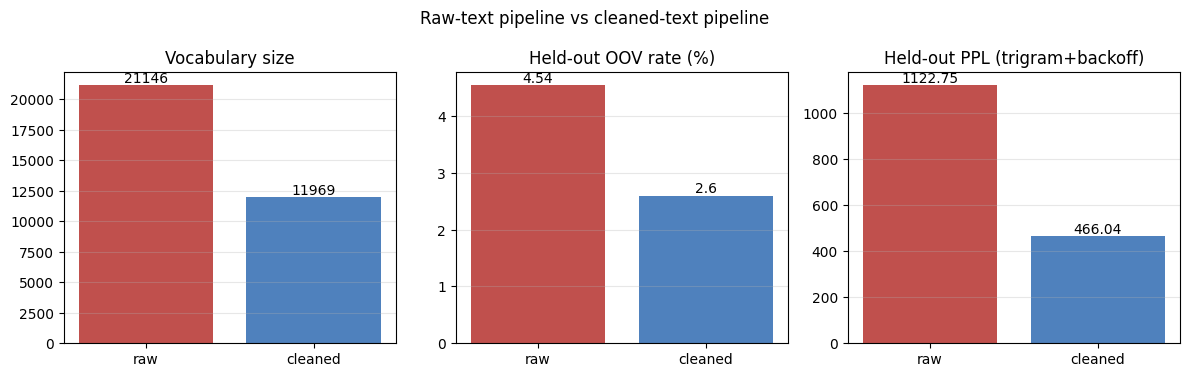

In [28]:
def raw_pipeline_sentences(ids):
    by_id = {a["article_number"]: a["body"] for a in articles}
    return [ln.split() for n in ids for ln in by_id[n].split("\n") if ln.split()]


raw_train = raw_pipeline_sentences([n for n in all_ids if n not in test_ids])
raw_test = raw_pipeline_sentences([n for n in all_ids if n in test_ids])
latin = re.compile(r"[A-Za-z]|www|http|[\U0001F000-\U0001FAFF]")


def pipeline_stats(name, tr, te, k_bi, k_tri):
    vocab = Counter(t for s in tr for t in s)
    test_toks = [t for s in te for t in s]
    b, t3 = BigramLM(tr, k_bi), TrigramLM(tr, k_tri)
    return {"pipeline": name, "train_tokens": sum(vocab.values()), "vocab": len(vocab),
            "OOV%": round(100 * sum(w not in vocab for w in test_toks) / len(test_toks), 2),
            "noisy_vocab%": round(100 * sum(bool(latin.search(w)) for w in vocab) / len(vocab), 2),
            "PPL_bigram": round(perplexity(b, te), 2), "PPL_trigram": round(perplexity(t3, te), 2)}, t3


raw_stats, raw_tri = pipeline_stats("raw", raw_train, raw_test, BEST_K["Bigram"], BEST_K["Trigram+backoff"])
cln_stats, _ = pipeline_stats("cleaned", train_sents, test_sents, BEST_K["Bigram"], BEST_K["Trigram+backoff"])
cmp_rows = [raw_stats, cln_stats]
cols = list(raw_stats)
print(" | ".join(f"{c:>12}" for c in cols))
for r in cmp_rows:
    print(" | ".join(f"{str(r[c]):>12}" for c in cols))

# generate one article from the raw-pipeline trigram to inspect noise leakage
MODELS["raw_trigram"] = raw_tri
_saved = preprocess_seed
preprocess_seed = lambda s: s.split()          # raw pipeline: seed is not preprocessed
TRAIN_SENT_SET_BACKUP = TRAIN_SENT_SET
TRAIN_SENT_SET = {tuple(s) for s in raw_train}
raw_art = generate_article(SEEDS[0], "raw_trigram", rng_seed=1000)
preprocess_seed, TRAIN_SENT_SET = _saved, TRAIN_SENT_SET_BACKUP
raw_toks = [t for s in raw_art["sentences"] for t in s]
leak = sum(bool(latin.search(t)) for t in raw_toks)
print(f"\nRaw-pipeline trigram article: {raw_art['n_words']} words, noisy tokens (Latin/URL/emoji): {leak} "
      f"({100*leak/len(raw_toks):.1f}%), diacritic tokens: {sum(bool(DIACRITICS_RE.search(t)) for t in raw_toks)}")
show_rtl("خام متن پائپ لائن سے تیار کردہ مضمون (موازنہ کے لیے)", [" ".join(" ".join(s) for s in raw_art["sentences"][:4])],
         "Raw pipeline, first 4 sentences only — note English words, URLs, captions and glued punctuation")

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, key, ttl in zip(axes, ["vocab", "OOV%", "PPL_trigram"], ["Vocabulary size", "Held-out OOV rate (%)", "Held-out PPL (trigram+backoff)"]):
    ax.bar(["raw", "cleaned"], [raw_stats[key], cln_stats[key]], color=["#c0504d", "#4f81bd"])
    ax.set_title(ttl); ax.grid(axis="y", alpha=.3)
    for i, v in enumerate([raw_stats[key], cln_stats[key]]):
        ax.text(i, v, f"{round(v, 2)}", ha="center", va="bottom")
plt.suptitle("Raw-text pipeline vs cleaned-text pipeline"); plt.tight_layout()
plt.savefig("plots/raw_vs_cleaned.png", dpi=150); plt.show()

### 7.3 Bigram vs Trigram with backoff

   model |       PPL_bi |      PPL_tri |    distinct2 | rep_trigram% |  verb_final% | full_context% | copies_rejected |  heldout_PPL
  bigram |       59.007 |     1251.087 |        0.965 |        0.633 |       69.067 |        100.0 |          0.0 |       228.52
 trigram |       58.443 |        43.79 |        0.979 |        0.133 |         66.4 |        100.0 |          0.0 |       466.04


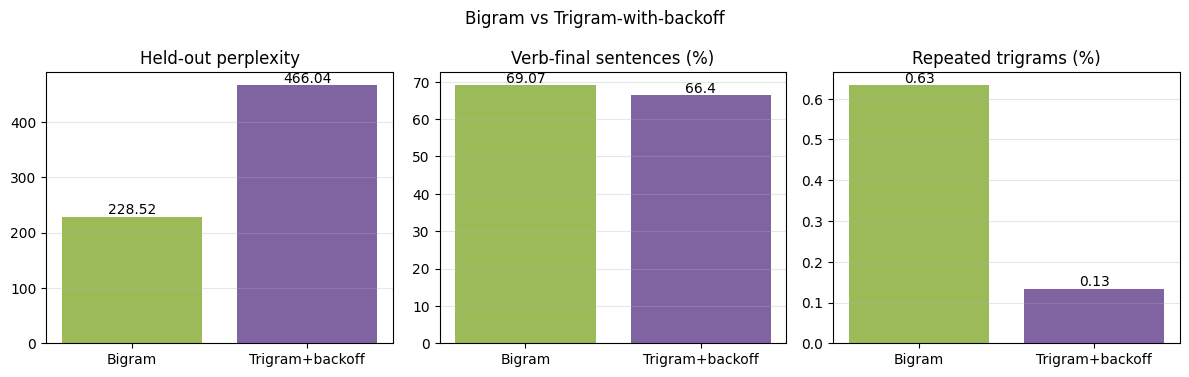

Observed in this run:
 - held-out perplexity: trigram+backoff 466.04 vs bigram 228.52 (-104% higher)
 - verb-final sentences: trigram 66.4% vs bigram 69.067%
 - repeated trigrams: trigram 0.133% vs bigram 0.633%; distinct-2: 0.979 vs 0.965
 - copied sentences rejected by the originality guard (mean/article): trigram 0.0 vs bigram 0.0


In [29]:
def mean(xs):
    return sum(xs) / len(xs)


bt = {}
for m in ["bigram", "trigram"]:
    rows = [r for r in eval_rows if r["article"].startswith(m)]
    bt[m] = {k: round(mean([r[k] for r in rows]), 3) for k in ["PPL_bi", "PPL_tri", "distinct2", "rep_trigram%", "verb_final%", "full_context%", "copies_rejected"]}
bt["bigram"]["heldout_PPL"] = round(ppl_table[BEST_K["Bigram"]]["Bigram"], 2)
bt["trigram"]["heldout_PPL"] = round(ppl_table[BEST_K["Trigram+backoff"]]["Trigram+backoff"], 2)
cols = list(bt["bigram"])
print(f"{'model':>8} | " + " | ".join(f"{c:>12}" for c in cols))
for m in bt:
    print(f"{m:>8} | " + " | ".join(f"{str(bt[m][c]):>12}" for c in cols))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, key, ttl in zip(axes, ["heldout_PPL", "verb_final%", "rep_trigram%"],
                        ["Held-out perplexity", "Verb-final sentences (%)", "Repeated trigrams (%)"]):
    vals = [bt["bigram"][key], bt["trigram"][key]]
    ax.bar(["Bigram", "Trigram+backoff"], vals, color=["#9bbb59", "#8064a2"]); ax.set_title(ttl); ax.grid(axis="y", alpha=.3)
    for i, v in enumerate(vals):
        ax.text(i, v, f"{round(v, 2)}", ha="center", va="bottom")
plt.suptitle("Bigram vs Trigram-with-backoff"); plt.tight_layout()
plt.savefig("plots/bigram_vs_trigram.png", dpi=150); plt.show()

b, t = bt["bigram"], bt["trigram"]
print("Observed in this run:")
print(f" - held-out perplexity: trigram+backoff {t['heldout_PPL']} vs bigram {b['heldout_PPL']} "
      f"({100*(b['heldout_PPL']-t['heldout_PPL'])/b['heldout_PPL']:.0f}% {'lower' if t['heldout_PPL']<b['heldout_PPL'] else 'higher'})")
print(f" - verb-final sentences: trigram {t['verb_final%']}% vs bigram {b['verb_final%']}%")
print(f" - repeated trigrams: trigram {t['rep_trigram%']}% vs bigram {b['rep_trigram%']}%; distinct-2: {t['distinct2']} vs {b['distinct2']}")
print(f" - copied sentences rejected by the originality guard (mean/article): trigram {t['copies_rejected']} vs bigram {b['copies_rejected']}")

In [30]:
# Save results for the report generator
results = {
    "data_source": DATA_SOURCE, "n_articles": len(articles), "n_sentences": n_sents, "n_tokens": n_toks,
    "vocab_surface": len(surface_vocab), "vocab_lemma": len(lemma_vocab),
    "vocab_final": len(Counter(t for v in processed.values() for s in v for t in s)),
    "ppl_table": {str(k): v for k, v in ppl_table.items()}, "best_k": BEST_K,
    "backoff_levels_heldout": {str(l): lvl[l] / tot for l in (3, 2, 1)},
    "eval_rows": eval_rows, "raw_vs_cleaned": cmp_rows, "bigram_vs_trigram": bt,
    "raw_leak_pct": 100 * leak / len(raw_toks),
    "headlines": [detok(h) for _, h in headlines], "seeds": SEEDS,
    "articles": {m: [{"seed": a["seed"], "text": article_text(a), "n_words": a["n_words"],
                      "n_sentences": a["n_sentences"], "stats": {str(k): v for k, v in a["stats"].items()}}
                     for a in generated[m]] for m in generated},
}
json.dump(results, open("results.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)
with open("generated_outputs.txt", "w", encoding="utf-8") as f:
    for m in ["bigram", "trigram"]:
        for i, a in enumerate(generated[m], 1):
            f.write(f"===== {m.upper()} ARTICLE {i} | seed: {a['seed']} | {a['n_words']} words =====\n")
            f.write("\n\n".join(article_text(a)) + "\n\n")
    f.write("===== HEADLINES =====\n" + "\n".join(results["headlines"]) + "\n")
print("Saved results.json and generated_outputs.txt")

Saved results.json and generated_outputs.txt


### 10. Build the report PDF

In [34]:
!ls -F

cleaned.txt	       Metadata.json  results.json	     token_map.json
generated_outputs.txt  plots/	      sample_data/
make_report.py	       raw.txt	      scraped_articles.json


### Download all generated files



In [37]:
import zipfile
from google.colab import files

file_list = [
    'cleaned.txt',
    'Metadata.json',
    'results.json',
    'token_map.json',
    'generated_outputs.txt',
    'make_report.py',
    'raw.txt',
    'scraped_articles.json',
    'plots/ppl_vs_k.png',
    'plots/raw_vs_cleaned.png',
    'plots/bigram_vs_trigram.png'
]

zip_filename = 'download_archive.zip'
with zipfile.ZipFile(zip_filename, 'w') as zf:
    for file_name in file_list:
        if os.path.exists(file_name):
            zf.write(file_name)
            print(f"Added {file_name} to {zip_filename}")
        else:
            print(f"Warning: {file_name} not found and will not be included in the zip.")

files.download(zip_filename)
print(f"Successfully created and downloaded {zip_filename}")

Added cleaned.txt to download_archive.zip
Added Metadata.json to download_archive.zip
Added results.json to download_archive.zip
Added token_map.json to download_archive.zip
Added generated_outputs.txt to download_archive.zip
Added make_report.py to download_archive.zip
Added raw.txt to download_archive.zip
Added scraped_articles.json to download_archive.zip
Added plots/ppl_vs_k.png to download_archive.zip
Added plots/raw_vs_cleaned.png to download_archive.zip
Added plots/bigram_vs_trigram.png to download_archive.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Successfully created and downloaded download_archive.zip


In [36]:
import subprocess, sys
r = subprocess.run([sys.executable, "make_report.py"], capture_output=True, text=True)
print(r.stdout or r.stderr)

make_report.py: Starting report generation...
make_report.py: Successfully loaded results.json. Data source: BBC Urdu (live scrape)
make_report.py: Report generation finished.

